# CaloDiffusion — Pion High-Response Event: Exact Replay and Denoising Trace

## Purpose

This notebook investigates the unusually high-response pion shower:

- **Event ID:** `gen:pion:32.768GeV:0:106`
- **Generation seed:** `20260112`
- **Incident energy:** `32.768 GeV`
- **Saved deposited energy after the 10 MeV analysis cut:** approximately `52.372 GeV`
- **Response:** approximately `1.598`
- **Largest native-cell deposit:** `46.758 GeV` in native cell `523`

The notebook will:

1. Verify that the three existing fidelity ZIPs belong to the same controlled study.
2. Reconstruct the original 16-event generation batch containing the target event.
3. Retrieve the exact repository revision and checkpoint and verify their SHA-256 hashes.
4. Re-run only that original 16-event batch with the original seed.
5. Compare the replay with the archived native arrays and compare the repository decoder with an explicit inverse transform.
6. Trace the model's predicted-clean-shower estimate (`x0_hat`) at each reverse-diffusion update and track when the large cell deposit develops.

**This is not a new fidelity run.** It does not train or modify the model and does not generate a new independent sample. It attempts to reproduce one original batch exactly.

## Important interpretation

The intermediate `x0_hat` tensors are the model's current estimates of the final clean shower during denoising. They are **not physical partial showers** and are not required to conserve energy at every step. The 10 MeV threshold is applied only to the diagnostic observables. The model's own decoding cutoff remains unchanged.

The reference/checkpoint independence question is separate and remains unverified unless your guide confirms the provenance.

## 0. Runtime setup

Use Google Colab with a GPU if available. A CPU run may be very slow. The notebook needs internet access to fetch the exact Git revision and checkpoint.

In [ ]:
import os, io, json, zipfile, hashlib, random, shutil, subprocess, sys, contextlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import yaml
from scipy.special import expit

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

# Reproducibility settings used by the controlled validation workflow.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
if hasattr(torch.backends, "cuda"):
    torch.backends.cuda.matmul.allow_tf32 = False
if hasattr(torch.backends, "cudnn"):
    torch.backends.cudnn.allow_tf32 = False

os.environ["CALODIFF_DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"


PyTorch: 2.14.1+cu130
CUDA available: True
Device: cuda


## 1. Upload the three original pion fidelity ZIP files

Upload the files from generation seeds `20260110`, `20260111` and `20260112`. The replay target is in the third run, but all three manifests are checked for consistency.

In [ ]:
from google.colab import files
uploaded = files.upload()

if len(uploaded) != 3:
    raise ValueError(f"Please upload exactly the three pion fidelity ZIPs; received {len(uploaded)} files.")

EXPECTED_SEEDS = (20260110, 20260111, 20260112)
runs = {}

def _read_json(zf, member):
    return json.loads(zf.read(member).decode("utf-8"))

def _read_npz(zf, member):
    with np.load(io.BytesIO(zf.read(member)), allow_pickle=False) as a:
        return {k: a[k].copy() for k in a.files}

for uploaded_name, payload in uploaded.items():
    zf = zipfile.ZipFile(io.BytesIO(payload))
    manifest_members = [n for n in zf.namelist() if n.endswith("/manifest.json")]
    if len(manifest_members) != 1:
        raise ValueError(f"Expected one manifest in {uploaded_name}; found {len(manifest_members)}")
    manifest_member = manifest_members[0]
    root = manifest_member.rsplit("/", 1)[0]
    manifest = _read_json(zf, manifest_member)
    seed = int(manifest["seed_streams"]["generation_seed"])
    if seed in runs:
        raise ValueError(f"Duplicate generation seed {seed}")
    geometry = _read_json(zf, f"{root}/pion_geometry.json")
    runs[seed] = {
        "uploaded_name": uploaded_name,
        "zip": zf,
        "root": root,
        "manifest": manifest,
        "geometry": geometry,
    }

if tuple(sorted(runs)) != EXPECTED_SEEDS:
    raise ValueError(f"Expected seeds {EXPECTED_SEEDS}; found {tuple(sorted(runs))}")

manifest_rows = []
for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    manifest_rows.append({
        "generation_seed": seed,
        "revision": m["revision"],
        "checkpoint_sha256": m["checkpoints"]["pion"]["sha256"],
        "batch_size": m["config"]["batch_size"],
        "sample_offset": m["config"]["sample_offset"],
        "analysis_cut_GeV": m["analysis_cut_GeV_overrides"]["pion"],
        "reference_unseen_by_checkpoint": m["reference_is_unseen_by_checkpoint"],
    })
display(pd.DataFrame(manifest_rows))


Saving validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip to validated_calo_controlled_pion_partition20261120_generation20260110_20261111T062300492793Z_fidelity_20261111T064128440045Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip to validated_calo_controlled_pion_partition20261120_generation20260111_20261111T064222710362Z_fidelity_20261111T065944965723Z.zip
Saving validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip to validated_calo_controlled_pion_partition20261120_generation20260112_20261111T070027866892Z_fidelity_20261111T071834882647Z.zip


,generation_seed,revision,checkpoint_sha256,batch_size,sample_offset,analysis_cut_GeV,reference_unseen_by_checkpoint
0,20260110,00ebcc3534fc25eee0fe15361483833e0bca34e7,77fa86ea1ce6fefe90685019ad45ce13408a2ee33d3683...,16,2,0.01,False
1,20260111,00ebcc3534fc25eee0fe15361483833e0bca34e7,77fa86ea1ce6fefe90685019ad45ce13408a2ee33d3683...,16,2,0.01,False
2,20260112,00ebcc3534fc25eee0fe15361483833e0bca34e7,77fa86ea1ce6fefe90685019ad45ce13408a2ee33d3683...,16,2,0.01,False


## 2. Verify the controlled-run identity and load the target archive

The three runs must share the exact revision, checkpoint hash, source hashes, reference partition and donor hashes. The target is fixed to row 106 of `generator_run0` at 32.768 GeV in seed `20260112`.

In [ ]:
base_manifest = runs[EXPECTED_SEEDS[0]]["manifest"]
for seed in EXPECTED_SEEDS[1:]:
    m = runs[seed]["manifest"]
    for key, label in [
        ("revision", "repository revision"),
        ("source_sha256", "source-file hashes"),
        ("checkpoints", "checkpoint metadata"),
        ("partition_sha256", "reference partition hashes"),
        ("scale_donor_sha256", "scale-only donor hashes"),
    ]:
        if m[key] != base_manifest[key]:
            raise RuntimeError(f"Runs do not share the same {label}; seed {seed} differs.")

for seed in EXPECTED_SEEDS:
    m = runs[seed]["manifest"]
    assert int(m["config"]["batch_size"]) == 16
    assert int(m["config"]["sample_offset"]) == 2
    assert np.isclose(float(m["analysis_cut_GeV_overrides"]["pion"]), 0.01)

TARGET_SEED = 20260112
TARGET_ENERGY = 32.768
TARGET_RUN = 0
TARGET_ROW = 106
EXPECTED_EVENT_ID = "gen:pion:32.768GeV:0:106"
ANALYSIS_CUT_GEV = 0.01
MODEL_EXPECTED_ECUT_GEV = 1e-7
EXPECTED_NATIVE_CELLS = 533

zf = runs[TARGET_SEED]["zip"]
root = runs[TARGET_SEED]["root"]
array_member = f"{root}/arrays/pion_32.768GeV_generator_run0.npz"
archive = _read_npz(zf, array_member)

actual_event_id = str(archive["event_id"][TARGET_ROW])
if actual_event_id != EXPECTED_EVENT_ID:
    raise RuntimeError(f"Target mismatch: expected {EXPECTED_EVENT_ID}, found {actual_event_id}")
if archive["native"].shape != (300, EXPECTED_NATIVE_CELLS):
    raise ValueError(f"Unexpected native array shape: {archive['native'].shape}")

run_manifest = runs[TARGET_SEED]["manifest"]
BATCH_SIZE_ORIGINAL = int(run_manifest["config"]["batch_size"])
SAMPLE_OFFSET_ORIGINAL = int(run_manifest["config"]["sample_offset"])
chunk_start = (TARGET_ROW // BATCH_SIZE_ORIGINAL) * BATCH_SIZE_ORIGINAL
chunk_stop = min(chunk_start + BATCH_SIZE_ORIGINAL, len(archive["energy"]))
local_target = TARGET_ROW - chunk_start
replay_energies = np.asarray(archive["energy"][chunk_start:chunk_stop], dtype=np.float64)
archived_chunk = np.asarray(archive["native"][chunk_start:chunk_stop], dtype=np.float32)
archived_ids = archive["event_id"][chunk_start:chunk_stop].astype(str)

assert len(replay_energies) == 16
assert local_target == 10
assert np.allclose(replay_energies, TARGET_ENERGY)

print("Target event:", actual_event_id)
print("Incident energy:", replay_energies[local_target], "GeV")
print("Original batch rows:", chunk_start, "through", chunk_stop - 1)
print("Target position within batch:", local_target)
print("Archived raw native sum:", float(archived_chunk[local_target].sum()), "GeV")
print("Archived maximum cell:", float(archived_chunk[local_target].max()), "GeV")


Target event: gen:pion:32.768GeV:0:106
Incident energy: 32.768 GeV
Original batch rows: 96 through 111
Target position within batch: 10
Archived raw native sum: 52.54233932495117 GeV
Archived maximum cell: 46.757999420166016 GeV


## 3. Reconstruct the exact random seed used for the original batch

The controlled validation uses a nested SHA-256 seed derivation. First it derives the generation-run seed for the stratum and generation repeat; then it derives a separate seed for the 16-event chunk. Do not substitute a new seed.

In [ ]:
def derive_seed(master_seed, *parts):
    text = "|".join(map(str, (int(master_seed), *parts)))
    return int(hashlib.sha256(text.encode()).hexdigest()[:8], 16)

seed_base = derive_seed(TARGET_SEED, "baseline", "pion", "32.768GeV", TARGET_RUN)
chunk_seed = derive_seed(TARGET_SEED, seed_base, "chunk", chunk_start)

print("Generation seed:", TARGET_SEED)
print("Baseline seed:", seed_base)
print("Chunk start:", chunk_start)
print("Exact chunk RNG seed:", chunk_seed)
print("Original event IDs in this batch:")
for event_id in archived_ids:
    print(" ", event_id)


Generation seed: 20260112
Baseline seed: 2307365730
Chunk start: 96
Exact chunk RNG seed: 1260554060
Original event IDs in this batch:
  gen:pion:32.768GeV:0:96
  gen:pion:32.768GeV:0:97
  gen:pion:32.768GeV:0:98
  gen:pion:32.768GeV:0:99
  gen:pion:32.768GeV:0:100
  gen:pion:32.768GeV:0:101
  gen:pion:32.768GeV:0:102
  gen:pion:32.768GeV:0:103
  gen:pion:32.768GeV:0:104
  gen:pion:32.768GeV:0:105
  gen:pion:32.768GeV:0:106
  gen:pion:32.768GeV:0:107
  gen:pion:32.768GeV:0:108
  gen:pion:32.768GeV:0:109
  gen:pion:32.768GeV:0:110
  gen:pion:32.768GeV:0:111


## 4. Fetch the exact repository revision and checkpoint

The replay is only meaningful if the code and checkpoint match the fidelity-run manifest. This cell fetches the pinned Git commit, downloads the pion checkpoint through Git LFS if needed, and checks every source hash recorded in the manifest. If a hash does not match, stop; do not continue with a different checkpoint.

In [ ]:
REPO_URL = "https://github.com/Vishal21501/gen-hep-notebooks.git"
REPLAY_REPO = Path("/content/calo_pion_exact_replay_repo")
REVISION = run_manifest["revision"]
ROOT = REPLAY_REPO / "capstone" / "calodiffusion"
CHECKPOINT_REL = "paper_code/trained_models/dataset1_pion.pth"
clone_env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")

if not (REPLAY_REPO / ".git").exists():
    if REPLAY_REPO.exists():
        raise RuntimeError(f"{REPLAY_REPO} exists but is not a Git checkout. Restart Colab or remove it deliberately.")
    subprocess.run(
        ["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
         "--branch", "main", REPO_URL, str(REPLAY_REPO)],
        check=True, env=clone_env
    )
    subprocess.run(
        ["git", "-C", str(REPLAY_REPO), "sparse-checkout", "set", "capstone/calodiffusion"],
        check=True
    )

subprocess.run(["git", "-C", str(REPLAY_REPO), "fetch", "--depth", "1", "origin", REVISION],
               check=True, env=clone_env)
subprocess.run(["git", "-C", str(REPLAY_REPO), "checkout", "--detach", REVISION], check=True)
actual_revision = subprocess.check_output(
    ["git", "-C", str(REPLAY_REPO), "rev-parse", "HEAD"], text=True
).strip()
if actual_revision != REVISION:
    raise RuntimeError(f"Repository revision mismatch: expected {REVISION}, got {actual_revision}")


def sha256_file(path, block_size=4 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(block_size), b""):
            h.update(block)
    return h.hexdigest()


def is_lfs_pointer(path):
    if not path.is_file():
        return False
    with path.open("rb") as f:
        return f.read(160).startswith(b"version https://git-lfs.github.com/spec/v1")

checkpoint_path = ROOT / CHECKPOINT_REL
if is_lfs_pointer(checkpoint_path) or not checkpoint_path.exists():
    has_lfs = subprocess.run(["git", "lfs", "version"], capture_output=True).returncode == 0
    if not has_lfs:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=True)
    subprocess.run(["git", "-C", str(REPLAY_REPO), "lfs", "install", "--local"], check=True)
    subprocess.run(
        ["git", "-C", str(REPLAY_REPO), "lfs", "pull",
         "--include=capstone/calodiffusion/" + CHECKPOINT_REL, "--exclude="],
        check=True
    )

if not checkpoint_path.is_file() or is_lfs_pointer(checkpoint_path):
    raise FileNotFoundError("Pion checkpoint is missing or remains a Git LFS pointer.")

expected_checkpoint_sha = run_manifest["checkpoints"]["pion"]["sha256"]
actual_checkpoint_sha = sha256_file(checkpoint_path)
if actual_checkpoint_sha != expected_checkpoint_sha:
    raise RuntimeError(
        f"Checkpoint SHA-256 mismatch: expected {expected_checkpoint_sha}, got {actual_checkpoint_sha}"
    )

source_hash_rows = []
for rel_path, expected_hash in run_manifest["source_sha256"].items():
    source_path = ROOT / rel_path
    if not source_path.is_file():
        raise FileNotFoundError(f"Manifest source file is missing: {source_path}")
    actual_hash = sha256_file(source_path)
    source_hash_rows.append({
        "file": rel_path,
        "expected_sha256": expected_hash,
        "actual_sha256": actual_hash,
        "matches": actual_hash == expected_hash,
    })
    if actual_hash != expected_hash:
        raise RuntimeError(f"Source hash mismatch for {rel_path}")

display(pd.DataFrame(source_hash_rows))
print("PASS: exact repository revision, checkpoint and all manifest source files verified.")


,file,expected_sha256,actual_sha256,matches
0,calodiff_probe.py,bdbd39c507134bacb1352e528260315805385809a5b9fc...,bdbd39c507134bacb1352e528260315805385809a5b9fc...,True
1,paper_code/scripts/CaloDiffu.py,ca6f4afb913f0cc6ead100ee54762891f851f7a40358f0...,ca6f4afb913f0cc6ead100ee54762891f851f7a40358f0...,True
2,paper_code/scripts/consts.py,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,3fc6312ff243d3f80f1fefc69ce27cf975713652826141...,True
3,paper_code/scripts/models.py,8138376149ce1134609455ca8c29a043906b1a2b6a948f...,8138376149ce1134609455ca8c29a043906b1a2b6a948f...,True
4,paper_code/scripts/plot.py,b99a63c9a11872d39a1496bbf8fb61c701be1488fb7427...,b99a63c9a11872d39a1496bbf8fb61c701be1488fb7427...,True
5,paper_code/scripts/utils.py,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,d34325c1fa5029fa436359b8893095e11c12bdb70a27a1...,True
6,paper_code/configs/config_dataset1_photon.json,075799ddbe214e6e080751eaeb7cb8cbaf61ad23386766...,075799ddbe214e6e080751eaeb7cb8cbaf61ad23386766...,True
7,paper_code/configs/config_dataset1_pion.json,0e9178e26ca76cf9217cb08a9babad86d8f8b307a85114...,0e9178e26ca76cf9217cb08a9babad86d8f8b307a85114...,True
8,paper_code/configs/config_dataset2.json,aada27339b2ee253348d42b5f641da1d857add005c5598...,aada27339b2ee253348d42b5f641da1d857add005c5598...,True
9,paper_code/CaloChallenge/code/binning_dataset_...,30786d54defff3d45dada4f4ecb2a4600a1622b3ca2004...,30786d54defff3d45dada4f4ecb2a4600a1622b3ca2004...,True


PASS: exact repository revision, checkpoint and all manifest source files verified.


## 5. Load the verified pion model and inspect its configuration

The config file has a `.json` suffix but is YAML-compatible in this repository. We therefore read it with `yaml.safe_load`, not `json.loads`. The model cutoff is expected to remain `1e-7 GeV`; the separate `0.01 GeV` (10 MeV) threshold is for analysis only.

In [ ]:
wrapper_path = (ROOT / "calodiff_probe.py").resolve()
if "calodiff_probe" in sys.modules:
    loaded_path = Path(sys.modules["calodiff_probe"].__file__).resolve()
    if loaded_path != wrapper_path:
        raise RuntimeError(
            "A different calodiff_probe is already imported. Restart the Colab runtime and rerun from the beginning."
        )
else:
    sys.path.insert(0, str(ROOT))
    import calodiff_probe as cp

if Path(cp.__file__).resolve() != wrapper_path:
    raise RuntimeError("Imported calodiff_probe does not come from the verified repository revision.")

pion_cfg_path = ROOT / "paper_code/configs/config_dataset1_pion.json"
pion_cfg = yaml.safe_load(pion_cfg_path.read_text(encoding="utf-8"))
assert int(pion_cfg["DATASET_NUM"]) == 0
assert int(pion_cfg["SHAPE_ORIG"][-1]) == EXPECTED_NATIVE_CELLS
assert np.isclose(float(pion_cfg["MAXDEP"]), 3.1)
assert np.isclose(float(pion_cfg["ECUT"]), MODEL_EXPECTED_ECUT_GEV)
assert pion_cfg["SHOWERMAP"] == "logit-norm"

with contextlib.redirect_stdout(io.StringIO()):
    model = cp.load_model("pion")
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)

MAXDEP = float(model.config["MAXDEP"])
MODEL_ECUT_GEV = float(model.config["ECUT"])
DATASET_KEY = int(model.config["DATASET_NUM"]) + (10 if model._orig_shape else 0)
params = cp.utils.dataset_params[DATASET_KEY]
LOGIT_MEAN = float(params["logit_mean"])
LOGIT_STD = float(params["logit_std"])

assert model._orig_shape and model.NN_embed is not None
assert DATASET_KEY == 10
assert int(np.prod(model._data_shape)) == EXPECTED_NATIVE_CELLS
assert np.isclose(MAXDEP, 3.1)
assert np.isclose(MODEL_ECUT_GEV, MODEL_EXPECTED_ECUT_GEV)

print("Model loaded from:", wrapper_path)
print("Device:", cp.DEVICE)
print("MAXDEP:", MAXDEP)
print("Model ECUT:", MODEL_ECUT_GEV, "GeV")
print("Analysis cutoff:", ANALYSIS_CUT_GEV, "GeV")
print("Native cells:", EXPECTED_NATIVE_CELLS)


Model loaded from: /content/calo_pion_exact_replay_repo/capstone/calodiffusion/calodiff_probe.py
Device: cuda
MAXDEP: 3.1
Model ECUT: 1e-07 GeV
Analysis cutoff: 0.01 GeV
Native cells: 533


## 6. Build the verified native-cell map

The pion geometry has seven active XML layers and 533 native cells. This map is used only to label the trace plots and cell 523; it does not alter the model output.

In [ ]:
geometry = runs[TARGET_SEED]["geometry"]
layer_ids = geometry["layer_ids"]
n_angles = geometry["n_angles"]
radial_edges = geometry["radial_edges"]

cell_rows = []
layer_rows = []
offset = 0
for layer_ordinal, (layer_id, n_ang, edges) in enumerate(zip(layer_ids, n_angles, radial_edges)):
    edges = np.asarray(edges, dtype=float)
    n_radial = len(edges) - 1
    start = offset
    stop = start + int(n_ang) * n_radial
    layer_rows.append({
        "layer_ordinal": layer_ordinal,
        "layer_id": int(layer_id),
        "n_angles": int(n_ang),
        "n_radial": int(n_radial),
        "native_start": start,
        "native_stop_exclusive": stop,
    })
    for angle_index in range(int(n_ang)):
        for radial_bin in range(n_radial):
            idx = start + angle_index * n_radial + radial_bin
            cell_rows.append({
                "native_index": idx,
                "layer_ordinal": layer_ordinal,
                "layer_id": int(layer_id),
                "angle_index": angle_index,
                "radial_bin": radial_bin,
                "r_low_XML": float(edges[radial_bin]),
                "r_high_XML": float(edges[radial_bin + 1]),
                "r_center_XML": float(0.5 * (edges[radial_bin] + edges[radial_bin + 1])),
            })
    offset = stop

cell_map = pd.DataFrame(cell_rows)
layer_map = pd.DataFrame(layer_rows)
assert len(cell_map) == EXPECTED_NATIVE_CELLS
assert offset == EXPECTED_NATIVE_CELLS
cell_523 = cell_map.loc[cell_map.native_index == 523].iloc[0]
print("Native cells:", len(cell_map))
print("Layer count:", len(layer_map))
print("Cell 523 mapping:")
display(cell_map.loc[cell_map.native_index.between(518, 532)])
assert int(cell_523.layer_id) == 14 and int(cell_523.radial_bin) == 0


Native cells: 533
Layer count: 7
Cell 523 mapping:


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML
518,518,5,13,9,11,300.0,350.0,325.0
519,519,5,13,9,12,350.0,400.0,375.0
520,520,5,13,9,13,400.0,600.0,500.0
521,521,5,13,9,14,600.0,1000.0,800.0
522,522,5,13,9,15,1000.0,2000.0,1500.0
523,523,6,14,0,0,0.0,50.0,25.0
524,524,6,14,0,1,50.0,100.0,75.0
525,525,6,14,0,2,100.0,150.0,125.0
526,526,6,14,0,3,150.0,200.0,175.0
527,527,6,14,0,4,200.0,250.0,225.0


## 7. Reproduce the original 16-event generation batch

First run the ordinary sampler exactly as the validation notebook did. We then compare its final output with the saved batch. The explicit inverse transform is checked against the repository's own `cp.to_physical` decoder.

In [ ]:
def capture_rng():
    return {
        "cpu": torch.random.get_rng_state().clone(),
        "cuda": [s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
        "numpy": np.random.get_state(),
        "python": random.getstate(),
    }

def restore_rng(state):
    torch.random.set_rng_state(state["cpu"])
    if state["cuda"]:
        torch.cuda.set_rng_state_all(state["cuda"])
    np.random.set_state(state["numpy"])
    random.setstate(state["python"])

@contextlib.contextmanager
def rng_context(seed):
    old = capture_rng()
    try:
        torch.manual_seed(int(seed))
        np.random.seed(int(seed) % 2**32)
        random.seed(int(seed))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(seed))
        yield
    finally:
        restore_rng(old)


def decode_model_space(x, energies, apply_model_cut=True):
    arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
    arr = np.asarray(arr, dtype=np.float64).reshape(len(energies), -1)
    if not np.isfinite(arr).all():
        raise ValueError("Non-finite model-space output.")
    logits = arr * LOGIT_STD + LOGIT_MEAN
    fractions = (expit(logits) - 1e-6) / (1.0 - 2e-6)
    native = fractions * MAXDEP * np.asarray(energies, dtype=float).reshape(-1, 1)
    if native.shape[1] != EXPECTED_NATIVE_CELLS:
        raise ValueError(f"Expected 533 native cells; got {native.shape[1]}.")
    if apply_model_cut:
        native = np.where(native >= MODEL_ECUT_GEV, native, 0.0)
    return native


def relative_l1(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    return float(np.abs(a - b).sum() / max(np.abs(b).sum(), 1e-15))

E_cond = cp.encode_energy("pion", replay_energies)
with rng_context(chunk_seed), torch.inference_mode(), contextlib.redirect_stdout(io.StringIO()):
    ordinary_output = cp.sample(
        model, E_cond, num_steps=cp.NSTEPS,
        sample_offset=SAMPLE_OFFSET_ORIGINAL, debug=False
    )

repository_native = np.asarray(
    cp.to_physical(model, ordinary_output, replay_energies), dtype=np.float64
).reshape(len(replay_energies), EXPECTED_NATIVE_CELLS)
manual_native = decode_model_space(ordinary_output, replay_energies, apply_model_cut=True)

archive_rel_l1 = np.asarray([
    relative_l1(repository_native[i], archived_chunk[i])
    for i in range(len(replay_energies))
])
manual_rel_l1 = np.asarray([
    relative_l1(manual_native[i], repository_native[i])
    for i in range(len(replay_energies))
])
max_abs_cell_delta = np.max(np.abs(repository_native - archived_chunk), axis=1)

replay_batch_table = pd.DataFrame({
    "batch_row": np.arange(chunk_start, chunk_stop),
    "local_position": np.arange(len(replay_energies)),
    "event_id": archived_ids,
    "incident_energy_GeV": replay_energies,
    "replay_vs_archive_relative_L1": archive_rel_l1,
    "max_abs_cell_difference_GeV": max_abs_cell_delta,
    "manual_vs_repository_decoder_relative_L1": manual_rel_l1,
})
display(replay_batch_table)

TARGET_REPLAY_MATCH = bool(archive_rel_l1[local_target] < 5e-4)
WHOLE_BATCH_MATCH = bool(np.all(archive_rel_l1 < 5e-4))
DECODER_MATCH = bool(np.all(manual_rel_l1 < 5e-5))
print("Target relative L1:", archive_rel_l1[local_target])
print("Target maximum absolute cell difference (GeV):", max_abs_cell_delta[local_target])
print("Whole 16-event batch reproduced:", WHOLE_BATCH_MATCH)
print("Manual inverse agrees with repository decoder:", DECODER_MATCH)

if not DECODER_MATCH:
    raise RuntimeError("Decoder implementations disagree. Do not interpret the trace.")
if not TARGET_REPLAY_MATCH:
    raise RuntimeError("Target shower did not reproduce within the required tolerance. Do not interpret the trace.")
print("PASS: target shower reproduced from the original generation batch.")


dset 10


,batch_row,local_position,event_id,incident_energy_GeV,replay_vs_archive_relative_L1,max_abs_cell_difference_GeV,manual_vs_repository_decoder_relative_L1
0,96,0,gen:pion:32.768GeV:0:96,32.768,6.735116e-07,1.846313e-06,1.900966e-07
1,97,1,gen:pion:32.768GeV:0:97,32.768,1.351415e-06,4.591942e-06,2.105818e-07
2,98,2,gen:pion:32.768GeV:0:98,32.768,7.242153e-07,1.022339e-06,2.087288e-07
3,99,3,gen:pion:32.768GeV:0:99,32.768,7.568793e-07,3.971100e-06,1.939673e-07
4,100,4,gen:pion:32.768GeV:0:100,32.768,8.534724e-07,1.136303e-06,2.256372e-07
5,101,5,gen:pion:32.768GeV:0:101,32.768,1.132469e-06,1.379013e-06,1.958825e-07
6,102,6,gen:pion:32.768GeV:0:102,32.768,9.235294e-07,1.644135e-06,1.742444e-07
7,103,7,gen:pion:32.768GeV:0:103,32.768,8.743704e-07,9.403229e-07,1.892824e-07
8,104,8,gen:pion:32.768GeV:0:104,32.768,9.448187e-07,1.449108e-06,2.082030e-07
9,105,9,gen:pion:32.768GeV:0:105,32.768,7.692789e-07,1.611233e-06,1.697627e-07


Target relative L1: 1.878788982338317e-07
Target maximum absolute cell difference (GeV): 3.326416013749167e-06
Whole 16-event batch reproduced: True
Manual inverse agrees with repository decoder: True
PASS: target shower reproduced from the original generation batch.


## 8. Trace the predicted clean shower at every reverse-diffusion update

The sampler's `p_sample` method returns the next noisy state and (when `debug=True`) the current clean estimate `x0_hat`. We temporarily wrap this method to record `x0_hat` for the target event while preserving the original sampler call and random-number sequence. The wrapper is removed immediately after tracing.

In [ ]:
original_p_sample = model.p_sample
had_instance_method = "p_sample" in model.__dict__
previous_instance_method = model.__dict__.get("p_sample")
trace_states = []
trace_timesteps = []
TOTAL_UPDATES = cp.NSTEPS - SAMPLE_OFFSET_ORIGINAL

def wrapped_p_sample(x, E_arg, t, *args, **kwargs):
    if args:
        raise RuntimeError("Unexpected positional p_sample arguments; check the pinned sampler API.")
    if not torch.all(t == int(t[0].item())):
        raise RuntimeError("Mixed timesteps in replay batch are not supported by this trace wrapper.")
    completed = len(trace_states)
    expected_t = TOTAL_UPDATES - 1 - completed
    actual_t = int(t[0].item())
    if actual_t != expected_t:
        raise RuntimeError(f"Unexpected timestep schedule: got {actual_t}, expected {expected_t}.")

    wants_debug = bool(kwargs.get("debug", False))
    kwargs["debug"] = True
    x_prev, x0_hat = original_p_sample(x, E_arg, t, **kwargs)
    trace_states.append(x0_hat[local_target].detach().cpu().clone())
    trace_timesteps.append(actual_t)
    return (x_prev, x0_hat) if wants_debug else x_prev

model.p_sample = wrapped_p_sample
try:
    with rng_context(chunk_seed), torch.inference_mode(), contextlib.redirect_stdout(io.StringIO()):
        traced_output = cp.sample(
            model, E_cond, num_steps=cp.NSTEPS,
            sample_offset=SAMPLE_OFFSET_ORIGINAL, debug=False
        )
finally:
    if had_instance_method:
        model.p_sample = previous_instance_method
    else:
        delattr(model, "p_sample")

if len(trace_states) != TOTAL_UPDATES:
    raise RuntimeError(f"Expected {TOTAL_UPDATES} trace states, captured {len(trace_states)}.")

trace_neutral = bool(torch.allclose(traced_output, ordinary_output, rtol=2e-5, atol=2e-6))
trace_final_max_delta = float((traced_output.cpu() - ordinary_output.cpu()).abs().max().item())
print("Captured reverse updates:", len(trace_states))
print("Trace-neutral final model-space output:", trace_neutral)
print("Maximum final model-space difference:", trace_final_max_delta)
if not trace_neutral:
    warnings.warn("Tracing changed the final model-space output. Treat the trajectory as unverified.")


Captured reverse updates: 398
Trace-neutral final model-space output: True
Maximum final model-space difference: 0.0


## 9. Decode each `x0_hat` and build the trajectory table

For every reverse update we record:

- Total deposited energy and response after the **10 MeV analysis cut**.
- Native-cell occupancy.
- Energy fraction in the final XML layer (layer ID 14).
- Deposit in native cell 523.
- Largest cell and top-five-cell energy fraction.
- Mean layer ordinal and radial RMS in XML radial units.

The model's original `ECUT = 1e-7 GeV` is applied during decoding to reproduce the archived native arrays. The 10 MeV threshold is applied afterwards for analysis.

In [ ]:
def apply_analysis_cut(native):
    native = np.asarray(native, dtype=np.float64)
    return np.where(native >= ANALYSIS_CUT_GEV, native, 0.0)

CELL_LAYER_ORDINAL = cell_map["layer_ordinal"].to_numpy(dtype=int)
CELL_RADII = cell_map["r_center_XML"].to_numpy(dtype=float)
FINAL_LAYER_ORDINAL = int(layer_map.index[layer_map.layer_id == 14][0])

trajectory_rows = []
for update_number, (timestep, state) in enumerate(zip(trace_timesteps, trace_states), start=1):
    native_step = decode_model_space(
        state.reshape(1, -1), [replay_energies[local_target]], apply_model_cut=True
    )[0]
    kept = apply_analysis_cut(native_step)
    total = float(kept.sum())
    if total > 0:
        layer_energy = np.bincount(CELL_LAYER_ORDINAL, weights=kept, minlength=len(layer_map))
        depth = float(np.sum(layer_energy * np.arange(len(layer_energy))) / total)
        radial_rms = float(np.sqrt(np.sum(kept * CELL_RADII**2) / total))
        final_layer_fraction = float(layer_energy[FINAL_LAYER_ORDINAL] / total)
        order = np.sort(kept)[::-1]
        top5_fraction = float(order[:5].sum() / total)
        occupancy = float(np.count_nonzero(kept) / EXPECTED_NATIVE_CELLS)
    else:
        depth = radial_rms = final_layer_fraction = top5_fraction = np.nan
        occupancy = 0.0
        order = np.zeros(5)

    trajectory_rows.append({
        "completed_updates": update_number,
        "diffusion_timestep": int(timestep),
        "deposited_GeV_after_10MeV_cut": total,
        "response_after_10MeV_cut": total / float(replay_energies[local_target]),
        "occupancy_after_10MeV_cut": occupancy,
        "mean_layer_ordinal": depth,
        "radial_RMS_XML": radial_rms,
        "final_layer_14_energy_fraction": final_layer_fraction,
        "cell_523_GeV_after_10MeV_cut": float(kept[523]),
        "largest_cell_GeV_after_10MeV_cut": float(order[0]) if len(order) else 0.0,
        "top5_fraction_after_10MeV_cut": top5_fraction,
    })

trajectory_df = pd.DataFrame(trajectory_rows)
display(trajectory_df.iloc[
    sorted(set([0, len(trajectory_df)//4, len(trajectory_df)//2,
                3*len(trajectory_df)//4, len(trajectory_df)-1]))
].round(6))


,completed_updates,diffusion_timestep,deposited_GeV_after_10MeV_cut,response_after_10MeV_cut,occupancy_after_10MeV_cut,mean_layer_ordinal,radial_RMS_XML,final_layer_14_energy_fraction,cell_523_GeV_after_10MeV_cut,largest_cell_GeV_after_10MeV_cut,top5_fraction_after_10MeV_cut
0,1,397,284.607731,8.685539,0.476548,3.545002,185.121260,0.000105,0.000000,65.337045,0.604609
99,100,298,0.406848,0.012416,0.016886,4.560692,84.269980,0.668077,0.078629,0.104700,0.759490
199,200,198,17.037645,0.519948,0.045028,5.826788,52.148372,0.918807,11.934420,11.934420,0.944636
298,299,99,23.005350,0.702068,0.084428,5.792813,55.127895,0.899491,18.184975,18.184975,0.913485
397,398,0,52.372189,1.598272,0.080675,5.905099,42.030154,0.953334,46.758001,46.758001,0.954051


## 10. Visualise when the extreme deposit develops

The most useful curves are the total response, the deposit in cell 523, the final-layer energy fraction and the fraction of energy in the five largest cells. Sudden late growth in these quantities would show when the anomalous concentration appears in the model's clean estimates.

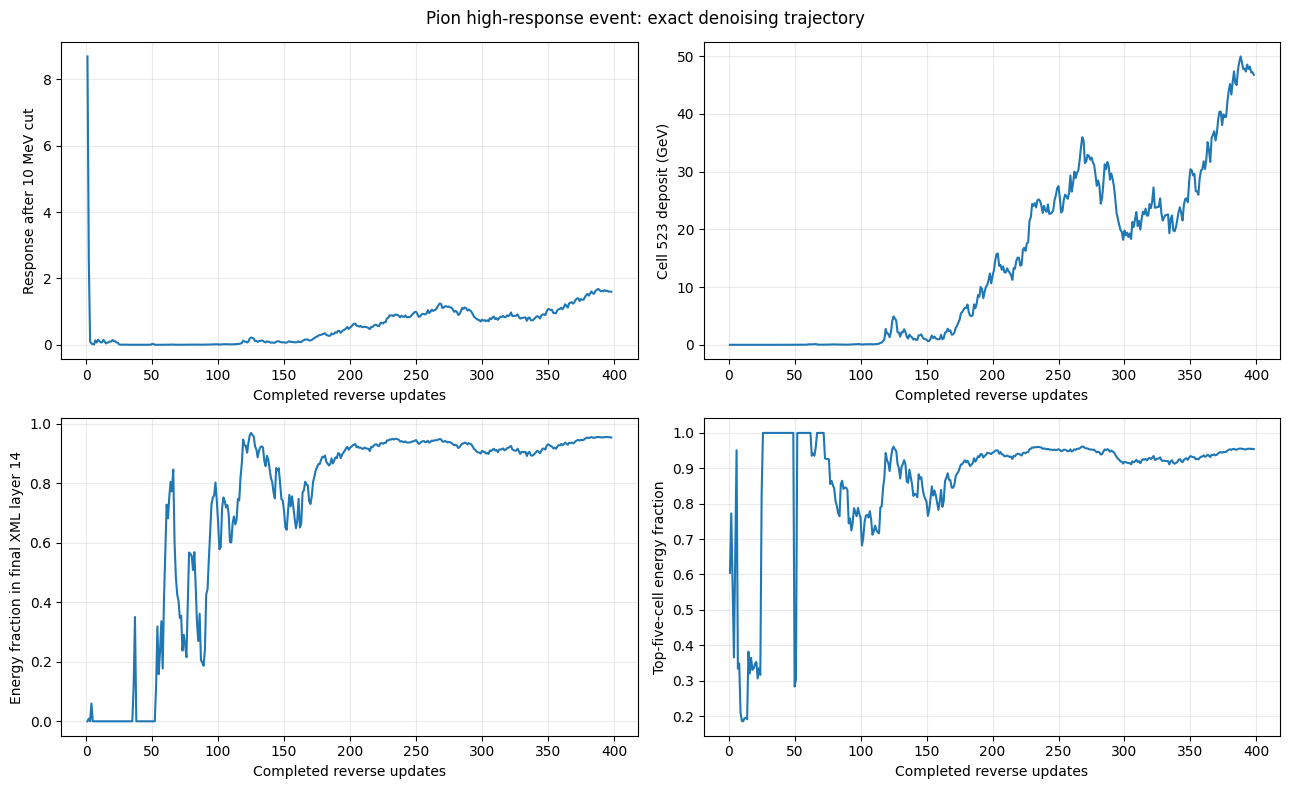

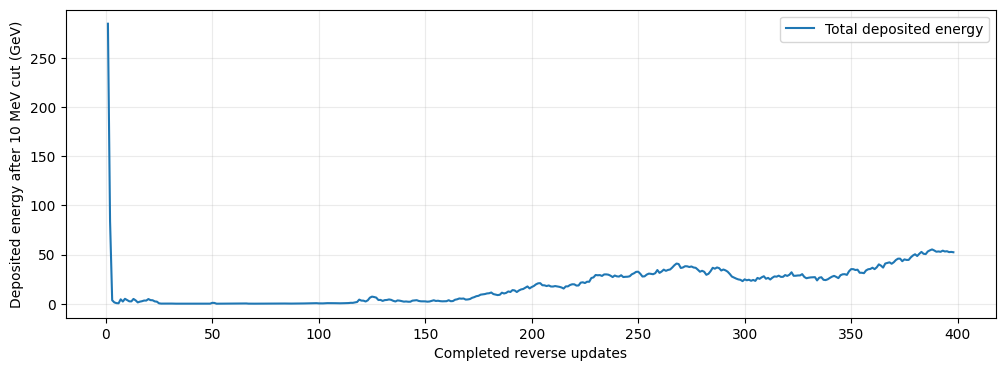

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plots = [
    (axes[0, 0], "response_after_10MeV_cut", "Response after 10 MeV cut"),
    (axes[0, 1], "cell_523_GeV_after_10MeV_cut", "Cell 523 deposit (GeV)"),
    (axes[1, 0], "final_layer_14_energy_fraction", "Energy fraction in final XML layer 14"),
    (axes[1, 1], "top5_fraction_after_10MeV_cut", "Top-five-cell energy fraction"),
]
for ax, column, ylabel in plots:
    ax.plot(trajectory_df["completed_updates"], trajectory_df[column], linewidth=1.5)
    ax.set_xlabel("Completed reverse updates")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
fig.suptitle("Pion high-response event: exact denoising trajectory")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(trajectory_df["completed_updates"], trajectory_df["deposited_GeV_after_10MeV_cut"], label="Total deposited energy")
ax.set_xlabel("Completed reverse updates")
ax.set_ylabel("Deposited energy after 10 MeV cut (GeV)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 11. Inspect the final shower and its dominant cells

This checks the final replayed shower against the archived shower and prints the top cells with their geometry labels. It helps establish whether cell 523 is isolated or accompanied by neighbouring deposits in the same final layer.

In [ ]:
replayed_target = repository_native[local_target]
saved_target = archived_chunk[local_target].astype(np.float64)
replayed_kept = apply_analysis_cut(replayed_target)
saved_kept = apply_analysis_cut(saved_target)

order = np.argsort(saved_kept)[::-1]
order = order[saved_kept[order] > 0][:20]
top_cells = cell_map.set_index("native_index").loc[order].reset_index()
top_cells["energy_GeV"] = saved_kept[order]
top_cells["fraction_of_shower"] = saved_kept[order] / saved_kept.sum()
top_cells["rank"] = np.arange(1, len(order) + 1)
display(top_cells.sort_values("rank"))

# Compare the replayed and archived target showers cell by cell.
cell_comparison = cell_map.copy()
cell_comparison["archived_GeV"] = saved_target
cell_comparison["replayed_GeV"] = replayed_target
cell_comparison["difference_GeV"] = replayed_target - saved_target
cell_comparison["archived_after_10MeV_GeV"] = saved_kept
cell_comparison["replayed_after_10MeV_GeV"] = replayed_kept

decoder_audit = pd.DataFrame([{
    "event_id": EXPECTED_EVENT_ID,
    "incident_energy_GeV": float(replay_energies[local_target]),
    "saved_raw_deposit_GeV": float(saved_target.sum()),
    "replayed_raw_deposit_GeV": float(replayed_target.sum()),
    "saved_deposit_after_10MeV_GeV": float(saved_kept.sum()),
    "replayed_deposit_after_10MeV_GeV": float(replayed_kept.sum()),
    "saved_response_after_10MeV": float(saved_kept.sum() / replay_energies[local_target]),
    "replayed_response_after_10MeV": float(replayed_kept.sum() / replay_energies[local_target]),
    "target_archive_relative_L1": relative_l1(replayed_target, saved_target),
    "manual_vs_repository_decoder_relative_L1": relative_l1(manual_native[local_target], repository_native[local_target]),
    "model_ECUT_GeV": MODEL_ECUT_GEV,
    "analysis_cut_GeV": ANALYSIS_CUT_GEV,
    "MAXDEP": MAXDEP,
    "native_cells": EXPECTED_NATIVE_CELLS,
    "trace_neutral": trace_neutral,
    "whole_batch_reproduced": WHOLE_BATCH_MATCH,
}])
display(decoder_audit.T)


,native_index,layer_ordinal,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_GeV,fraction_of_shower,rank
0,523,6,14,0,0,0.0,50.0,25.0,46.757999,0.892802,1
1,524,6,14,0,1,50.0,100.0,75.0,2.248994,0.042943,2
2,525,6,14,0,2,100.0,150.0,125.0,0.396661,0.007574,3
3,213,4,12,0,0,0.0,10.0,5.0,0.285116,0.005444,4
4,527,6,14,0,4,200.0,250.0,225.0,0.276968,0.005288,5
5,348,4,12,9,0,0.0,10.0,5.0,0.245080,0.004680,6
6,508,5,13,9,1,10.0,20.0,15.0,0.235809,0.004503,7
7,349,4,12,9,1,10.0,20.0,15.0,0.209727,0.004005,8
8,482,5,13,7,7,130.0,160.0,145.0,0.178306,0.003405,9
9,526,6,14,0,3,150.0,200.0,175.0,0.154621,0.002952,10


,0
event_id,gen:pion:32.768GeV:0:106
incident_energy_GeV,32.768
saved_raw_deposit_GeV,52.542337
replayed_raw_deposit_GeV,52.54233
saved_deposit_after_10MeV_GeV,52.372192
replayed_deposit_after_10MeV_GeV,52.372185
saved_response_after_10MeV,1.598272
replayed_response_after_10MeV,1.598272
target_archive_relative_L1,0.0
manual_vs_repository_decoder_relative_L1,0.0


## 12. Interpret the trajectory carefully

Use the output as follows:

- **Replay matches + decoder agrees + trace is neutral:** the replay and trajectory are technically trustworthy on this runtime.
- **Cell 523 grows mainly in late updates:** the extreme concentration is formed late in reverse denoising. This identifies *when*, not the physical reason *why*.
- **Cell 523 is already large in early clean estimates:** the concentration is present early in the model's predicted-clean trajectory.
- **Replay mismatch:** do not interpret the trace as an exact reconstruction. Check hardware/runtime differences, deterministic-kernel behaviour and the pinned source/checkpoint hashes.

A high deposited response is not automatically a decoder bug. The decoder's inverse transform maps model-space values to native deposits; it does not impose a global constraint that total deposited energy must equal incident energy.

## 13. Save the investigation outputs

The ZIP contains the batch replay table, target decoder audit, full denoising trajectory, cell map, top-cell table, cell-by-cell comparison and plots.

In [ ]:
OUTPUT_DIR = Path("/content/pion_high_response_replay_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

replay_batch_table.to_csv(OUTPUT_DIR / "pion_high_response_replay_batch.csv", index=False)
decoder_audit.to_csv(OUTPUT_DIR / "pion_high_response_decoder_audit.csv", index=False)
trajectory_df.to_csv(OUTPUT_DIR / "pion_high_response_denoising_trajectory.csv", index=False)
top_cells.to_csv(OUTPUT_DIR / "pion_high_response_top_cells.csv", index=False)
cell_comparison.to_csv(OUTPUT_DIR / "pion_high_response_cell_comparison.csv", index=False)
cell_map.to_csv(OUTPUT_DIR / "pion_native_cell_map.csv", index=False)

# Save figures explicitly.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, column, ylabel in [
    (axes[0, 0], "response_after_10MeV_cut", "Response after 10 MeV cut"),
    (axes[0, 1], "cell_523_GeV_after_10MeV_cut", "Cell 523 deposit (GeV)"),
    (axes[1, 0], "final_layer_14_energy_fraction", "Final layer 14 energy fraction"),
    (axes[1, 1], "top5_fraction_after_10MeV_cut", "Top-five-cell fraction"),
]:
    ax.plot(trajectory_df["completed_updates"], trajectory_df[column])
    ax.set_xlabel("Completed reverse updates")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
fig.suptitle("Pion high-response event: denoising trajectory")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pion_high_response_denoising_trajectory.png", dpi=170)
plt.close(fig)

summary = {
    "event_id": EXPECTED_EVENT_ID,
    "generation_seed": TARGET_SEED,
    "source_revision": REVISION,
    "checkpoint_sha256": actual_checkpoint_sha,
    "chunk_start": chunk_start,
    "chunk_stop_exclusive": chunk_stop,
    "chunk_seed": int(chunk_seed),
    "target_replay_match_relative_L1_lt_5e-4": TARGET_REPLAY_MATCH,
    "whole_batch_match_relative_L1_lt_5e-4": WHOLE_BATCH_MATCH,
    "decoder_match_relative_L1_lt_5e-5": DECODER_MATCH,
    "trace_neutral": trace_neutral,
    "trace_final_max_model_space_delta": trace_final_max_delta,
    "reference_is_unseen_by_checkpoint": bool(run_manifest["reference_is_unseen_by_checkpoint"]),
    "model_ECUT_GeV": MODEL_ECUT_GEV,
    "analysis_cut_GeV": ANALYSIS_CUT_GEV,
}
(OUTPUT_DIR / "replay_summary.json").write_text(json.dumps(summary, indent=2))

zip_path = shutil.make_archive(str(OUTPUT_DIR), "zip", OUTPUT_DIR)
print("Saved:", zip_path)
print(json.dumps(summary, indent=2))
files.download(zip_path)


Saved: /content/pion_high_response_replay_outputs.zip
{
  "event_id": "gen:pion:32.768GeV:0:106",
  "generation_seed": 20260112,
  "source_revision": "00ebcc3534fc25eee0fe15361483833e0bca34e7",
  "checkpoint_sha256": "77fa86ea1ce6fefe90685019ad45ce13408a2ee33d36833221b4187d0bde82e4",
  "chunk_start": 96,
  "chunk_stop_exclusive": 112,
  "chunk_seed": 1260554060,
  "target_replay_match_relative_L1_lt_5e-4": true,
  "whole_batch_match_relative_L1_lt_5e-4": true,
  "decoder_match_relative_L1_lt_5e-5": true,
  "trace_neutral": true,
  "trace_final_max_model_space_delta": 0.0,
  "reference_is_unseen_by_checkpoint": false,
  "model_ECUT_GeV": 1e-07,
  "analysis_cut_GeV": 0.01
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Final decision checklist

Before interpreting the physics, confirm:

- [ ] Repository revision matches the fidelity manifest.
- [ ] Pion checkpoint SHA-256 matches the fidelity manifest.
- [ ] All recorded source-file hashes match.
- [ ] Repository decoder agrees with the explicit inverse transform.
- [ ] Target event reproduces within relative L1 `< 5e-4`.
- [ ] Trace is neutral: traced and ordinary final model-space outputs agree.

If the target replay and trace checks pass, report **when the extreme cell concentration develops**. Do not claim that the trajectory proves a specific physical mechanism. The reference/checkpoint independence status remains unverified until confirmed by your guide.